# Day 2 - Từ annotation YOLO đến detector YOLO26

Notebook này chạy **sau** khi nhãn 50 ảnh train đã qua cổng gold-set. Tập `eval` 10 ảnh không được dùng để train.

Quy trình chuẩn: bạn **fork repo đề bài**, gán nhãn, **commit và push** `dataset/labels/train/` lên repo của mình, rồi chỉ cần dán URL repo vào `REPO_URL` ở cell đầu tiên — Colab sẽ tự clone repo, train và đánh giá, không cần upload file.

Bài cá nhân. Hạn nộp: 11:59 trưa ngày hôm sau buổi lab (UTC+7); ca 09/11/2026 nộp trước 11:59 ngày 10/11/2026.

## Kiểm tra trước khi chạy

- Đã **fork repo đề bài**, gán nhãn và **commit + push** `dataset/labels/train/` lên repo của bạn.
- Ở cell tiếp theo, dán **URL repo của bạn** vào `REPO_URL` — notebook tự clone, không cần upload file.
- Không có `gold_train_labels/` trong repo.
- Chạy từ trên xuống dưới; giữ nguyên `data.yaml` và split eval.
- mAP đo model; F1/IoU ở script trước đó đo chất lượng nhãn con người.

In [ ]:
%pip -q install -U ultralytics

from pathlib import Path
import json
import os
import shutil
import subprocess
import torch
import yaml
from ultralytics import YOLO

# ==================================================================
# Bước 1 (bắt buộc): dán URL repo fork của bạn vào REPO_URL
#
# Dòng chuẩn của bài:
#   1. Fork repo đề bài, đổi tên theo chuẩn nộp
#      (K5-L2-DAY02-HoVaTen-MSSV-ObjectDetection).
#   2. Gán nhãn 50 ảnh, commit và push dataset/labels/train/ lên repo của bạn.
#   3. Mở notebook này trong Colab, dán URL repo, chạy cell này:
#      notebook tự clone repo của bạn và train, không cần upload file.
#
# Ví dụ:
#   REPO_URL = 'https://github.com/your-username/K5-L2-DAY02-HoVanA-20241234-ObjectDetection'
# ==================================================================
REPO_URL = 'https://github.com/doantunglam/K5-L2-Day02-DoanTungLam-2A202603227-ObjectDetection'
assert 'your-username' not in REPO_URL, (
    'Hãy dán URL repo fork của bạn (đã commit + push nhãn) vào REPO_URL.'
)

# Trên Colab clone về /content/Day2-Lab; chạy ngoài Colab thì dùng ./Day2-Lab.
LAB_ROOT = Path('/content/Day2-Lab') if Path('/content').is_dir() else Path('Day2-Lab')

if LAB_ROOT.exists():
    # Chạy lại cell trong cùng phiên Colab: khôi phục các file đã được sửa
    # (ví dụ data.yaml ở lần chạy trước) rồi kéo bản mới nhất từ GitHub.
    # Nếu thư mục không phải bản clone của repo, xóa /content/Day2-Lab rồi chạy lại.
    print('Đã có sẵn thư mục, pull nội dung mới nhất từ GitHub...')
    subprocess.run(['git', '-C', str(LAB_ROOT), 'checkout', '--', '.'], check=True)
    subprocess.run(['git', '-C', str(LAB_ROOT), 'pull', '--ff-only'], check=True)
else:
    print(f'Clone {REPO_URL} -> {LAB_ROOT}')
    env = {**os.environ, 'GIT_TERMINAL_PROMPT': '0'}
    try:
        subprocess.run(['git', 'clone', REPO_URL, str(LAB_ROOT)], check=True, env=env)
    except subprocess.CalledProcessError:
        # Repo private: clone bằng token tài khoản GitHub của bạn trong Colab.
        # Nếu chưa: menu Tools -> sign in to GitHub, rồi chạy lại cell này.
        from google.colab import auth
        token = auth.user_token('github')
        auth_url = REPO_URL.replace('https://github.com', f'https://{token}@github.com')
        subprocess.run(['git', 'clone', auth_url, str(LAB_ROOT)], check=True)

last_commit = subprocess.run(
    ['git', '-C', str(LAB_ROOT), 'log', '-1', '--oneline'],
    check=True, capture_output=True, text=True,
).stdout.strip()
print('commit mới nhất trong repo:', last_commit)

DATA_YAML = LAB_ROOT / 'data.yaml'
TRAIN_IMAGES = LAB_ROOT / 'dataset/images/train'
TRAIN_LABELS = LAB_ROOT / 'dataset/labels/train'
EVAL_IMAGES = LAB_ROOT / 'dataset/images/eval'
EVAL_LABELS = LAB_ROOT / 'dataset/labels/eval'
RUNS = LAB_ROOT / 'outputs/yolo26_runs'
DEVICE = 0 if torch.cuda.is_available() else 'cpu'

# Ultralytics resolves a relative `path:` in data.yaml against its own global
# datasets dir, not against data.yaml's own folder. Rewrite it to an absolute
# path so training works regardless of where the repo was cloned.
_data_cfg = yaml.safe_load(DATA_YAML.read_text(encoding='utf-8'))
_data_cfg['path'] = str((LAB_ROOT / 'dataset').resolve())
DATA_YAML.write_text(yaml.dump(_data_cfg, allow_unicode=True, sort_keys=False), encoding='utf-8')

print('LAB_ROOT:', LAB_ROOT.resolve())
print('device:', DEVICE)

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\Admin\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Clone https://github.com/doantunglam/K5-L2-Day02-DoanTungLam-2A202603227-ObjectDetection -> Day2-Lab
commit mới nhất trong repo: dde727b Modify GUIDELINE_MINI.md
LAB_ROOT: D:\K5-L2-Day02-DoanTungLam-2A202603227-ObjectDetection\notebooks\Day2-Lab
device: cpu


In [3]:
def image_stems(directory):
    return {p.stem for ext in ('*.jpg', '*.jpeg', '*.png') for p in directory.glob(ext)}

train_images = image_stems(TRAIN_IMAGES)
train_labels = {p.stem for p in TRAIN_LABELS.glob('*.txt')}
eval_images = image_stems(EVAL_IMAGES)
eval_labels = {p.stem for p in EVAL_LABELS.glob('*.txt')}
assert len(train_images) == 50, f' cần 50 train images, thấy {len(train_images)}'
assert train_images == train_labels, f'train images/labels lệch: {sorted(train_images ^ train_labels)[:5]}'
assert len(eval_images) == 10 and eval_images == eval_labels, 'eval phải đủ 10 ảnh và nhãn'
print(f'OK: {len(train_images)} train + {len(eval_images)} eval; eval không đi vào train.')

OK: 50 train + 10 eval; eval không đi vào train.


## Huấn luyện

Bài thực hành dùng checkpoint `yolo26n.pt`. Với 50 ảnh, dùng model nano và ít epoch để minh họa vòng lặp dữ liệu; thời gian/metric không dùng làm benchmark sản phẩm.

In [4]:
model = YOLO('yolo26n.pt')
train_result = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=-1,
    device=DEVICE,
    project=str(RUNS),
    name='vehicle_annotation',
    exist_ok=True,
    seed=20260909,
    plots=True,
)
BEST = Path(model.trainer.best)
print('best checkpoint:', BEST)

Ultralytics 8.4.208  Python-3.12.6 torch-2.15.0+cpu CPU (AMD Ryzen 9 7945HX with Radeon Graphics)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=Day2-Lab\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=vehicle_annotation, nbs=64, nms=None, opset=None, opti

## Đánh giá đúng tập eval

`data.yaml` trỏ `val` tới 10 ảnh eval đã có nhãn. Không đổi `val` sang train để làm đẹp mAP. Ghi lại mAP50, mAP50-95, precision và recall.

Tập `eval` cũng được dùng làm validation trong quá trình train và chọn `best.pt`, nên không phải test set độc lập.

In [5]:
best_model = YOLO(str(BEST))
metrics = best_model.val(data=str(DATA_YAML), split='val', device=DEVICE, plots=True, project=str(RUNS), name='vehicle_eval', exist_ok=True)
summary = {
    'precision': float(metrics.box.mp),
    'recall': float(metrics.box.mr),
    'map50': float(metrics.box.map50),
    'map50_95': float(metrics.box.map),
    'eval_images': len(eval_images),
    'checkpoint': str(BEST),
}
metrics_path = LAB_ROOT / 'outputs/model_eval_metrics.json'
metrics_path.parent.mkdir(parents=True, exist_ok=True)
metrics_path.write_text(json.dumps(summary, indent=2) + '\n')
print(json.dumps(summary, indent=2))

Ultralytics 8.4.208  Python-3.12.6 torch-2.15.0+cpu CPU (AMD Ryzen 9 7945HX with Radeon Graphics)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 532.8±94.7 MB/s, size: 67.1 KB)
val: Scanning D:\K5-L2-Day02-DoanTungLam-2A202603227-ObjectDetection\notebooks\Day2-Lab\dataset\labels\eval.cache... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.9it/s 0.3s
                   all         10        113      0.448      0.267      0.277      0.204
                   car         10         94      0.698      0.702      0.738      0.521
                 truck          5          5      0.809        0.2      0.279      0.235
                   bus          2          2          0          0     0.0171    0.00853
                   van          6         12      0.283      0.167     0.

In [6]:
# Kiểm tra trực quan một vài ảnh eval; đây là bước bắt buộc trong báo cáo.
prediction_dir = LAB_ROOT / 'outputs/eval_predictions'
results = best_model.predict(source=str(EVAL_IMAGES), conf=0.25, device=DEVICE, save=True, project=str(prediction_dir), name='visuals', exist_ok=True)
PRED_SAVE_DIR = Path(results[0].save_dir)
print('predictions saved to:', PRED_SAVE_DIR)
archive = shutil.make_archive(str(LAB_ROOT / 'outputs/day2_colab_outputs'), 'zip', LAB_ROOT / 'outputs')
print('Đã tạo:', archive)


image 1/10 d:\K5-L2-Day02-DoanTungLam-2A202603227-ObjectDetection\notebooks\Day2-Lab\dataset\images\eval\drive_051.jpg: 640x640 11 cars, 1 bus, 1 van, 45.8ms
image 2/10 d:\K5-L2-Day02-DoanTungLam-2A202603227-ObjectDetection\notebooks\Day2-Lab\dataset\images\eval\drive_052.jpg: 640x640 18 cars, 2 buss, 26.6ms
image 3/10 d:\K5-L2-Day02-DoanTungLam-2A202603227-ObjectDetection\notebooks\Day2-Lab\dataset\images\eval\drive_053.jpg: 640x640 11 cars, 2 buss, 1 van, 28.4ms
image 4/10 d:\K5-L2-Day02-DoanTungLam-2A202603227-ObjectDetection\notebooks\Day2-Lab\dataset\images\eval\drive_054.jpg: 640x640 7 cars, 1 van, 26.3ms
image 5/10 d:\K5-L2-Day02-DoanTungLam-2A202603227-ObjectDetection\notebooks\Day2-Lab\dataset\images\eval\drive_055.jpg: 640x640 6 cars, 1 van, 27.4ms
image 6/10 d:\K5-L2-Day02-DoanTungLam-2A202603227-ObjectDetection\notebooks\Day2-Lab\dataset\images\eval\drive_056.jpg: 640x640 18 cars, 1 bus, 3 vans, 25.6ms
image 7/10 d:\K5-L2-Day02-DoanTungLam-2A202603227-ObjectDetection\noteb

## Xem trực tiếp kết quả dự đoán

Hiển thị 10 ảnh eval kèm box dự đoán ngay trong notebook, không cần tải file `.zip` về mới xem được.

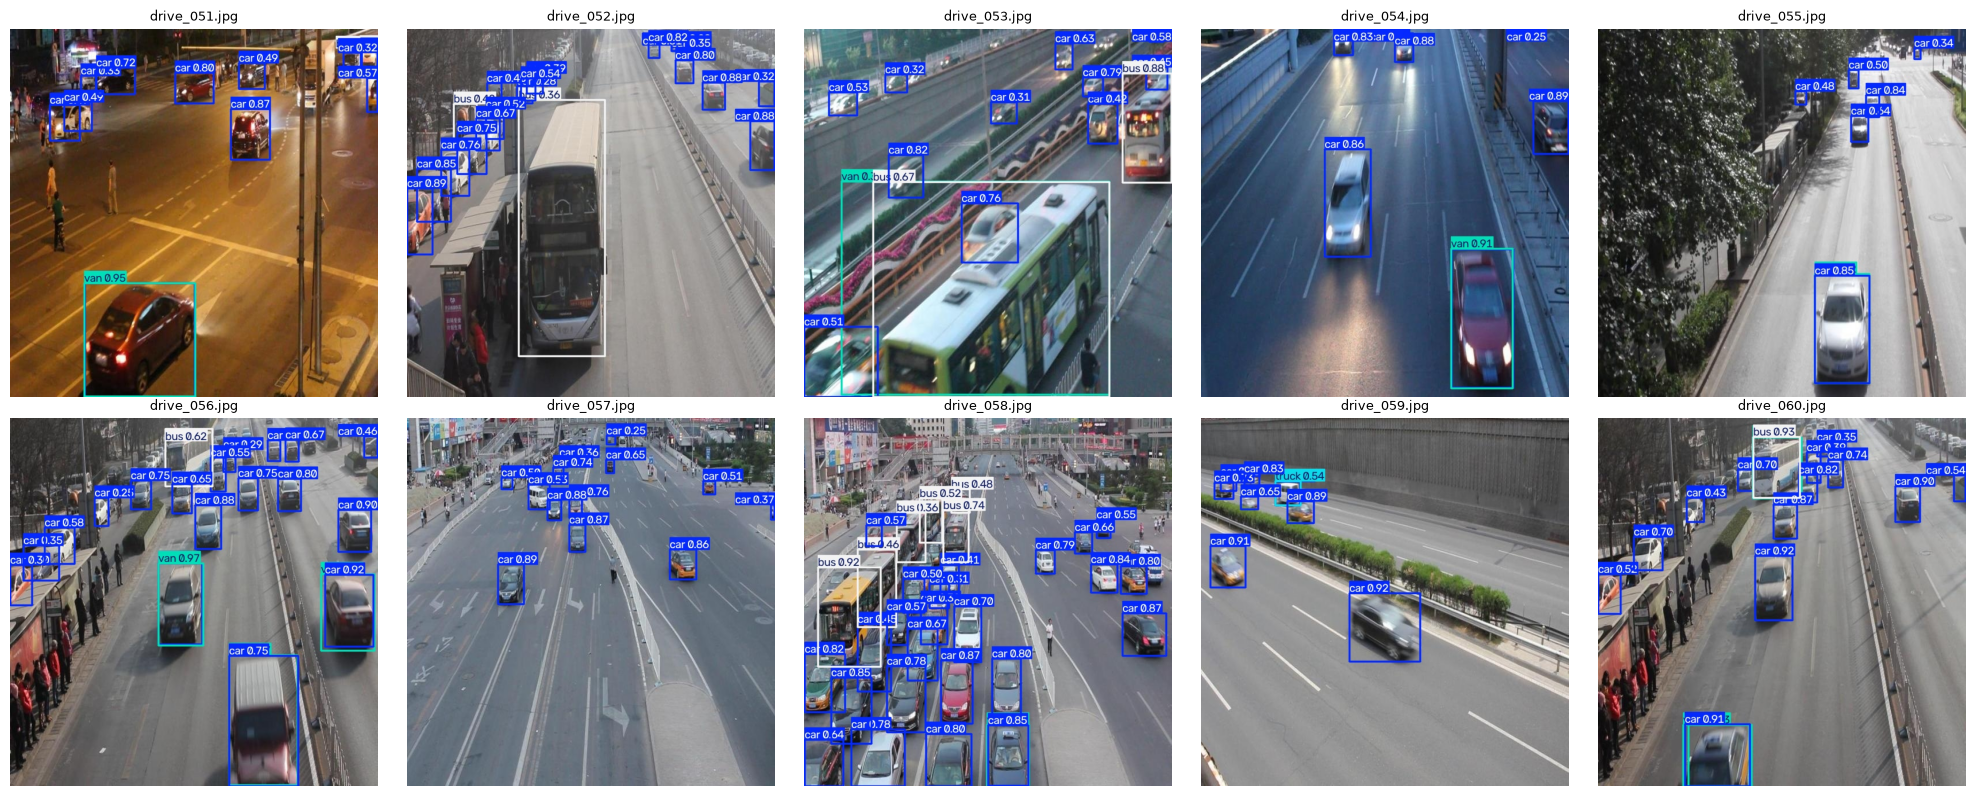

In [7]:
import math
import matplotlib.pyplot as plt
from PIL import Image

pred_images = sorted(PRED_SAVE_DIR.glob('*.jpg'))
cols = 5
rows = math.ceil(len(pred_images) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
for ax, img_path in zip(axes.flat, pred_images):
    ax.imshow(Image.open(img_path))
    ax.set_title(img_path.name, fontsize=9)
    ax.axis('off')
for ax in axes.flat[len(pred_images):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## Câu hỏi phân tích để nộp

1. Lớp nào có recall thấp nhất? Chỉ ra một ảnh eval minh họa.
- `bus` có recall thấp nhất: 0.000 (0/2). Ví dụ, `drive_051.jpg` có nhãn bus trong ground truth nhưng không được tính là phát hiện đúng khi đánh giá. Dù phần dự đoán trực quan có hiện một box `bus`, box đó có thể không khớp đủ với nhãn về vị trí hoặc IoU.
2. Nếu mAP50 cao nhưng mAP50-95 thấp, box đang gặp vấn đề gì?
- Khi mAP50 cao nhưng mAP50–95 thấp, mô hình có thể nhận ra đúng vật thể nhưng box chưa khớp sát với vật thể ở các ngưỡng IoU nghiêm ngặt hơn. Cần kiểm tra box có ôm đúng mép xe theo guideline không: không thiếu các phần như gương, cản, nóc, bánh xe; không lấy thêm bóng hoặc hàng hóa. Trong lần chạy này, mAP50 là 0.277 và mAP50–95 là 0.204, nên cả hai chỉ số đều còn thấp.
3. Có lỗi `truck`/`bus`/`van`/`car` nào liên quan tới guideline không?
- Có dấu hiệu nhầm giữa các lớp, nhưng chưa đủ căn cứ để kết luận nhãn bị gán sai. Kết quả cho thấy truck có recall 0.200, bus 0.000 và van 0.167; ma trận nhầm lẫn cũng có trường hợp truck bị dự đoán thành car, bus thành car, và van thành bus. Những trường hợp này đáng được rà lại theo guideline—đặc biệt là ranh giới giữa car/van/bus và tiêu chí truck có cabin tách biệt với phần chở hàng. Đây có thể là lỗi dự đoán của mô hình, không nhất thiết là lỗi annotation.
4. Vì sao không dùng 10 ảnh eval để train dù chúng có nhãn?
- Không dùng 10 ảnh eval để train vì như vậy mô hình đã học các ảnh dùng để đánh giá, khiến kết quả kém khách quan và khó biết khả năng tổng quát hóa. Trong notebook, 10 ảnh này được dùng làm validation để đánh giá và chọn `best.pt`; do đó, chúng không phải tập test độc lập hoàn toàn.